# Data Mining Lab: Book Recommender with a Medallion Data Lake
**Dataset:** Book-Crossing (Users, Books, Book-Ratings)  
**Pipeline:** Raw files -> Bronze (untouched) -> Silver (cleaned) -> Gold (model-ready) -> Item-based collaborative filtering

Run all cells top to bottom in Google Colab (Runtime -> Run all).

## Step 1: Set up the data lake and build the Bronze layer

In [4]:
import re, zipfile, urllib.request
from collections import defaultdict
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.neighbors import NearestNeighbors

RAW, BRONZE, SILVER, GOLD = Path("raw"), Path("bronze"), Path("silver"), Path("gold")
for p in (RAW, BRONZE, SILVER, GOLD):
    p.mkdir(exist_ok=True)
print("Data lake folders:", [p.name + "/" for p in (BRONZE, SILVER, GOLD)])

Data lake folders: ['bronze/', 'silver/', 'gold/']


In [6]:
URL = "https://cdn.freecodecamp.org/project-data/books/book-crossings.zip"

# Configure a User-Agent to prevent the HTTP 403 Forbidden error
opener = urllib.request.build_opener()
opener.addheaders = [('User-Agent', 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)')]
urllib.request.install_opener(opener)

# Download + unzip only if the CSVs are not already there
if not [p for p in RAW.rglob("*.csv") if "__MACOSX" not in p.parts]:
    urllib.request.urlretrieve(URL, RAW / "book-crossings.zip")
    with zipfile.ZipFile(RAW / "book-crossings.zip") as z:
        z.extractall(RAW)

def find_csv(name):
    return next(p for p in RAW.rglob("*.csv")
                if p.name.lower() == name.lower() and "__MACOSX" not in p.parts)

paths = {"users": find_csv("BX-Users.csv"),
         "books": find_csv("BX-Books.csv"),
         "ratings": find_csv("BX-Book-Ratings.csv")}
paths

{'users': PosixPath('raw/BX-Users.csv'),
 'books': PosixPath('raw/BX-Books.csv'),
 'ratings': PosixPath('raw/BX-Book-Ratings.csv')}

In [8]:
def read_raw(path):
    # Files are ';' separated and latin-1 encoded (not UTF-8).
    # Everything is read as text (dtype=str) so that NOTHING is converted or
    # altered at this stage; typing happens in Silver.
    # on_bad_lines='skip' only drops physically broken lines (bad quoting).
    return pd.read_csv(path, sep=";", encoding="latin-1", dtype=str,
                       quotechar='"', escapechar="\\", on_bad_lines="skip")

bronze = {name: read_raw(p) for name, p in paths.items()}

ingestion_ts = pd.Timestamp.now(tz="UTC")
for name, df in bronze.items():
    df["ingestion_timestamp"] = ingestion_ts          # only column we add
    df.to_parquet(BRONZE / f"{name}.parquet", index=False)
    print(f"bronze/{name}.parquet saved  ->  {df.shape[0]:,} rows, {df.shape[1]} cols")

bronze/users.parquet saved  ->  278,858 rows, 4 cols
bronze/books.parquet saved  ->  271,379 rows, 9 cols
bronze/ratings.parquet saved  ->  1,149,780 rows, 4 cols


*No cleaning is done in Bronze. It is an exact copy of the source plus `ingestion_timestamp`.*

## Step 2: Explore the Bronze data (EDA)

In [9]:
users_b   = pd.read_parquet(BRONZE / "users.parquet")
books_b   = pd.read_parquet(BRONZE / "books.parquet")
ratings_b = pd.read_parquet(BRONZE / "ratings.parquet")

for name, df in [("users", users_b), ("books", books_b), ("ratings", ratings_b)]:
    print(f"\n===== {name}: shape = {df.shape} =====")
    print(pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum()}))
    print("duplicate rows:", df.drop(columns="ingestion_timestamp").duplicated().sum())


===== users: shape = (278858, 4) =====
                                   dtype  missing
User-ID                           object        0
Location                          object        0
Age                               object   110762
ingestion_timestamp  datetime64[us, UTC]        0
duplicate rows: 0

===== books: shape = (271379, 9) =====
                                   dtype  missing
ISBN                              object        0
Book-Title                        object        0
Book-Author                       object        2
Year-Of-Publication               object        0
Publisher                         object        2
Image-URL-S                       object        0
Image-URL-M                       object        0
Image-URL-L                       object        0
ingestion_timestamp  datetime64[us, UTC]        0
duplicate rows: 0

===== ratings: shape = (1149780, 4) =====
                                   dtype  missing
User-ID                           object 

**EDA finding 1 - Shape, types, missing values.**  
*Found:* about 278k users, 271k books and 1.15M ratings; every column is text because Bronze keeps raw values; `Age` is missing for roughly 40% of users, and a few books lack author/publisher. *Silver action:* cast IDs/ratings/age/year to numeric types, fill missing ages with the median, and drop books with no title.

Book-Rating
0     716109
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64

Ratings equal to 0 (implicit): 716,109  (62.3% of all ratings)


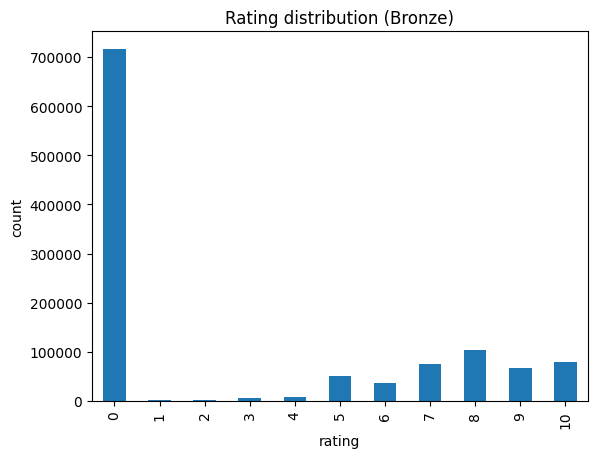

In [10]:
r = pd.to_numeric(ratings_b["Book-Rating"], errors="coerce")
print(r.value_counts().sort_index())
print(f"\nRatings equal to 0 (implicit): {(r == 0).sum():,}  ({(r == 0).mean():.1%} of all ratings)")
r.value_counts().sort_index().plot(kind="bar", title="Rating distribution (Bronze)")
plt.xlabel("rating"); plt.ylabel("count"); plt.show()

**EDA finding 2 - Ratings.**  
*Found:* the largest bar is 0 (about 60%+ of rows) - it means "no explicit rating", not a bad rating; among 1-10, ratings skew high (8 is the mode). *Silver action:* remove all 0 ratings and keep only 1-10.

count    168096.000000
mean         34.751434
std          14.428097
min           0.000000
25%          24.000000
50%          32.000000
75%          44.000000
max         244.000000
Name: Age, dtype: float64
Age < 5   : 882 | Age > 100 : 366 | Age missing: 110762

 count    271379.000000
mean       1959.756050
std         258.011363
min           0.000000
25%        1989.000000
50%        1995.000000
75%        2000.000000
max        2050.000000
Name: Year-Of-Publication, dtype: float64
Year == 0: 4619 | Year > 2026: 11 | non-numeric/missing: 0


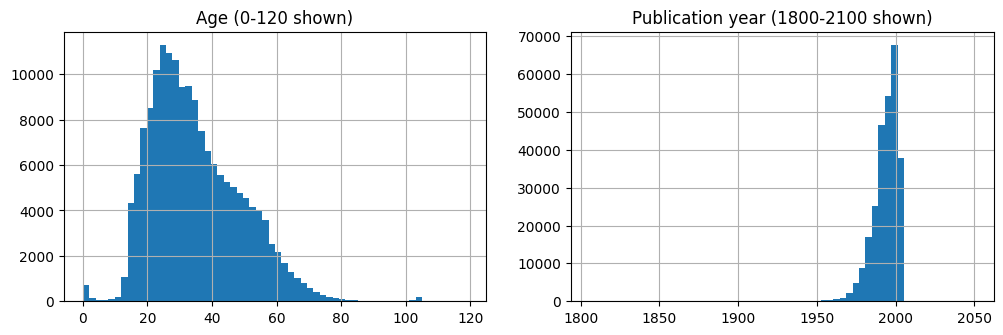

In [11]:
age = pd.to_numeric(users_b["Age"], errors="coerce")
print(age.describe())
print("Age < 5   :", (age < 5).sum(), "| Age > 100 :", (age > 100).sum(), "| Age missing:", age.isna().sum())

year = pd.to_numeric(books_b["Year-Of-Publication"], errors="coerce")
cur = datetime.now().year
print("\n", year.describe())
print(f"Year == 0: {(year == 0).sum()} | Year > {cur}: {(year > cur).sum()} | non-numeric/missing: {year.isna().sum()}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
age[(age >= 0) & (age <= 120)].hist(bins=60, ax=ax[0]); ax[0].set_title("Age (0-120 shown)")
year[(year > 1800) & (year <= 2100)].hist(bins=60, ax=ax[1]); ax[1].set_title("Publication year (1800-2100 shown)")
plt.show()

**EDA finding 3 - Ages and publication years.**  
*Found:* impossible ages (0, 1, and values up to 200+), and years equal to 0 or in the future (e.g. 2030+), plus a few non-numeric years from shifted rows. *Silver action:* set ages <5 or >100 to null then fill with the median; set years of 0 or after the current year to null.

Explicit ratings per USER:
 count    77805.000000
mean         5.573819
std         44.001879
min          1.000000
25%          1.000000
50%          1.000000
75%          3.000000
max       8524.000000
dtype: float64

Explicit ratings per BOOK:
 count    185973.000000
mean          2.331903
std           6.834667
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max         707.000000
dtype: float64

Users with < 10 ratings: 90.6% | Books with < 10 ratings: 97.0%


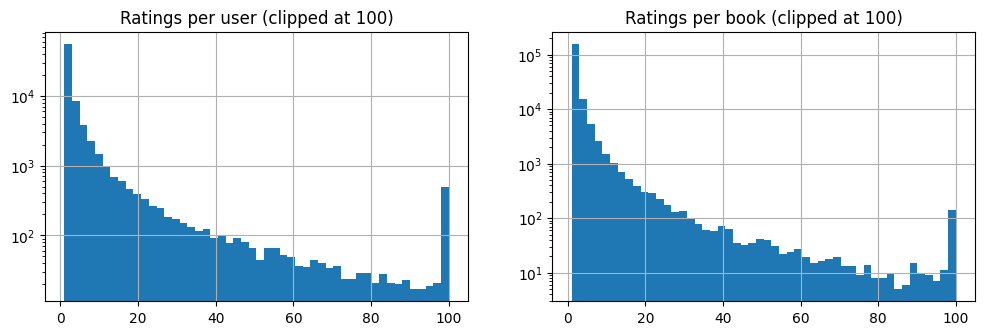

,min_ratings,users,books,ratings_kept,ratings_kept_%
0,1,77805,185973,433671,100.0
1,5,14220,14535,152280,35.1
2,10,7334,5645,90556,20.9
3,20,3704,2179,47610,11.0
4,50,1332,537,14288,3.3


In [12]:
exp = ratings_b.assign(rating=pd.to_numeric(ratings_b["Book-Rating"], errors="coerce"))
exp = exp[exp["rating"] > 0]          # explicit only (just for EDA)

per_user = exp.groupby("User-ID").size()
per_book = exp.groupby("ISBN").size()
print("Explicit ratings per USER:\n", per_user.describe())
print("\nExplicit ratings per BOOK:\n", per_book.describe())
print(f"\nUsers with < 10 ratings: {(per_user < 10).mean():.1%} | Books with < 10 ratings: {(per_book < 10).mean():.1%}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
per_user.clip(upper=100).hist(bins=50, ax=ax[0]); ax[0].set_yscale("log"); ax[0].set_title("Ratings per user (clipped at 100)")
per_book.clip(upper=100).hist(bins=50, ax=ax[1]); ax[1].set_yscale("log"); ax[1].set_title("Ratings per book (clipped at 100)")
plt.show()

# Threshold justification table (single pass, explicit ratings only)
rows = []
for t in [1, 5, 10, 20, 50]:
    u_ok = per_user[per_user >= t].index
    b_ok = per_book[per_book >= t].index
    kept = exp[exp["User-ID"].isin(u_ok) & exp["ISBN"].isin(b_ok)]
    rows.append({"min_ratings": t, "users": len(u_ok), "books": len(b_ok), "ratings_kept": len(kept),
                 "ratings_kept_%": round(100 * len(kept) / len(exp), 1)})
pd.DataFrame(rows)

**EDA finding 4 - Ratings per user / per book.**  
*Found:* extremely long-tailed - the median user and the median book have only 1 explicit rating, and the large majority have fewer than 10. *Silver action:* apply a minimum-ratings threshold. **I choose 10 for both users and books**: the table above shows that 10 keeps a meaningful share of the explicit ratings while discarding the huge tail of 1-3 rating users/books, which cannot give reliable cosine similarity (a book with 1-2 raters has an almost meaningless vector). Going to 20 or 50 throws away much more data and leaves too few books; going to 5 leaves a very noisy matrix. The filter is applied repeatedly until it is stable, because removing users can push books below 10 and vice versa.

In [13]:
n_users_all, n_books_all = users_b["User-ID"].nunique(), books_b["ISBN"].nunique()
sparsity_all = 1 - len(ratings_b) / (n_users_all * n_books_all)
sparsity_exp = 1 - len(exp) / (per_user.size * per_book.size)
print(f"Full grid (all users x all books):           {sparsity_all:.5%} empty  ->  {100 - sparsity_all*100:.5f}% filled")
print(f"Active grid (users/books with explicit ratings): {sparsity_exp:.5%} empty  ->  {100 - sparsity_exp*100:.5f}% filled")

Full grid (all users x all books):           99.99848% empty  ->  0.00152% filled
Active grid (users/books with explicit ratings): 99.99700% empty  ->  0.00300% filled


**EDA finding 5 - Matrix sparsity.**  
*Found:* well under 0.01% of all possible user-book pairs have a rating (>99.99% empty). *Gold action:* store the user-book matrix as a SciPy **sparse CSR matrix**; a dense matrix would need hundreds of GB.

## Step 3: Clean the data and build the Silver layer

In [14]:
MIN_USER_RATINGS = 10   # chosen + justified in EDA finding 4
MIN_BOOK_RATINGS = 10

def clean_text(s, case=None):
    """Collapse repeated spaces, strip, treat placeholder strings as null, standardise case."""
    s = s.astype("string").str.replace(r"\s+", " ", regex=True).str.strip()
    s = s.mask(s.str.lower().isin(["", "nan", "null", "none", "n/a"]))
    if case == "lower":
        s = s.str.lower()
    elif case == "title":
        s = s.str.title()
    return s

users   = pd.read_parquet(BRONZE / "users.parquet").drop(columns="ingestion_timestamp")
books   = pd.read_parquet(BRONZE / "books.parquet").drop(columns="ingestion_timestamp")
ratings = pd.read_parquet(BRONZE / "ratings.parquet").drop(columns="ingestion_timestamp")
log = {}

### 3a. Users: duplicates, age fix, location split

In [15]:
users = users.rename(columns={"User-ID": "user_id", "Location": "location", "Age": "age"})
n0 = len(users)
users = users.drop_duplicates()
users["user_id"] = pd.to_numeric(users["user_id"], errors="coerce")
users = users.dropna(subset=["user_id"]).astype({"user_id": "int64"}).drop_duplicates("user_id")
log["users: duplicates/invalid ids removed"] = n0 - len(users)

# Age: <5 or >100 -> null, then fill with the median
age = pd.to_numeric(users["age"], errors="coerce")
age = age.where(age.between(5, 100))
median_age = age.median()
users["age"] = age.fillna(median_age).round().astype(int)
print("median age used for filling:", median_age)

# Location "city, state, country" -> 3 columns
def split_loc(x):
    if pd.isna(x):
        return (None, None, None)
    p = [t.strip() for t in str(x).split(",")]
    city = p[0] or None
    country = p[-1] if len(p) > 1 else None
    state = ", ".join(p[1:-1]) or None if len(p) > 2 else None
    return (city, state, country)

users["location"] = clean_text(users["location"], "lower")
parts = users["location"].map(split_loc)
for i, col in enumerate(["city", "state", "country"]):
    users[col] = clean_text(parts.map(lambda t: t[i]), "lower")
users = users.drop(columns="location")
users.head()

median age used for filling: 32.0


,user_id,age,city,state,country
0,1,32,nyc,new york,usa
1,2,18,stockton,california,usa
2,3,32,moscow,yukon territory,russia
3,4,17,porto,v.n.gaia,portugal
4,5,32,farnborough,hants,united kingdom


### 3b. Books: duplicates, publication year, text cleaning, drop image columns

In [16]:
books = books.rename(columns={"ISBN": "isbn", "Book-Title": "title", "Book-Author": "author",
                              "Year-Of-Publication": "year", "Publisher": "publisher"})
img_cols = [c for c in books.columns if c.lower().startswith("image")]
books = books.drop(columns=img_cols)                                   # image URLs not needed
n0 = len(books)
books = books.drop_duplicates()
books["isbn"] = clean_text(books["isbn"]).str.upper()
books = books.dropna(subset=["isbn"]).drop_duplicates("isbn")
log["books: duplicates removed"] = n0 - len(books)

year = pd.to_numeric(books["year"], errors="coerce")
current_year = datetime.now().year
bad_year = (year == 0) | (year > current_year) | year.isna()
books["year"] = year.where(~bad_year).astype("Int64")                 # 0 / future -> null
log["books: invalid years set to null"] = int(bad_year.sum())

for c, case in [("title", "title"), ("author", "title"), ("publisher", "title")]:
    books[c] = clean_text(books[c], case)
books = books.dropna(subset=["title"])                                # a book needs a title
books.head()

,isbn,title,author,year,publisher
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press
1,0002005018,Clara Callan,Richard Bruce Wright,2001,Harperflamingo Canada
2,0060973129,Decision In Normandy,Carlo D'Este,1991,Harperperennial
3,0374157065,Flu: The Story Of The Great Influenza Pandemic...,Gina Bari Kolata,1999,Farrar Straus Giroux
4,0393045218,The Mummies Of Urumchi,E. J. W. Barber,1999,W. W. Norton &Amp; Company


### 3c. Ratings: duplicates, remove 0s, referential integrity, minimum-ratings filter

In [17]:
ratings = ratings.rename(columns={"User-ID": "user_id", "ISBN": "isbn", "Book-Rating": "rating"})
n_raw = len(ratings)
ratings = ratings.drop_duplicates()
ratings["user_id"] = pd.to_numeric(ratings["user_id"], errors="coerce")
ratings["rating"] = pd.to_numeric(ratings["rating"], errors="coerce")
ratings["isbn"] = clean_text(ratings["isbn"]).str.upper()
ratings = ratings.dropna(subset=["user_id", "isbn", "rating"]).astype({"user_id": "int64", "rating": "int64"})
ratings = ratings.drop_duplicates(["user_id", "isbn"], keep="last")    # one rating per user-book
log["ratings: duplicates removed"] = n_raw - len(ratings)

n = len(ratings)
ratings = ratings[ratings["rating"].between(1, 10)]                    # drops the 0s
log["ratings: zeros / out-of-range removed"] = n - len(ratings)

n = len(ratings)
ratings = ratings[ratings["user_id"].isin(users["user_id"]) & ratings["isbn"].isin(books["isbn"])]
log["ratings: orphans (user/book missing) removed"] = n - len(ratings)

# Minimum-ratings filter, repeated until stable
n = len(ratings)
while True:
    u_cnt = ratings.groupby("user_id")["isbn"].transform("size")
    b_cnt = ratings.groupby("isbn")["user_id"].transform("size")
    keep = (u_cnt >= MIN_USER_RATINGS) & (b_cnt >= MIN_BOOK_RATINGS)
    if keep.all():
        break
    ratings = ratings[keep]
log[f"ratings: removed by min-ratings filter (user>={MIN_USER_RATINGS}, book>={MIN_BOOK_RATINGS})"] = n - len(ratings)

# Keep only users and books that survived
users = users[users["user_id"].isin(ratings["user_id"])].reset_index(drop=True)
books = books[books["isbn"].isin(ratings["isbn"])].reset_index(drop=True)
ratings = ratings.reset_index(drop=True)

users.to_parquet(SILVER / "users.parquet", index=False)
books.to_parquet(SILVER / "books.parquet", index=False)
ratings.to_parquet(SILVER / "ratings.parquet", index=False)

print(pd.Series(log).to_string())
print(f"\nSilver sizes -> users: {len(users):,} | books: {len(books):,} | ratings: {len(ratings):,}")

users: duplicates/invalid ids removed                               0
books: duplicates removed                                         315
books: invalid years set to null                                 4623
ratings: duplicates removed                                         0
ratings: zeros / out-of-range removed                          716109
ratings: orphans (user/book missing) removed                    49818
ratings: removed by min-ratings filter (user>=10, book>=10)    342384

Silver sizes -> users: 1,820 | books: 2,030 | ratings: 41,469


## Step 4: Build the Gold layer

In [18]:
users   = pd.read_parquet(SILVER / "users.parquet")
books   = pd.read_parquet(SILVER / "books.parquet")
ratings = pd.read_parquet(SILVER / "ratings.parquet")

user_ids = np.sort(ratings["user_id"].unique())
isbns    = np.sort(ratings["isbn"].unique())
user_pos = pd.Series(np.arange(len(user_ids)), index=user_ids)
book_pos = pd.Series(np.arange(len(isbns)), index=isbns)

# 1) Sparse user x book rating matrix (rows = users, cols = books)
rows = ratings["user_id"].map(user_pos).to_numpy()
cols = ratings["isbn"].map(book_pos).to_numpy()
matrix = sparse.csr_matrix((ratings["rating"].to_numpy(dtype=np.float32), (rows, cols)),
                           shape=(len(user_ids), len(isbns)))
sparse.save_npz(GOLD / "user_book_matrix.npz", matrix)

# Index maps so matrix positions can be turned back into ids
pd.DataFrame({"user_idx": np.arange(len(user_ids)), "user_id": user_ids}).to_parquet(GOLD / "user_index.parquet", index=False)

# 2) Book lookup table (id, title, author)
book_lookup = (books.set_index("isbn").loc[isbns, ["title", "author"]].reset_index())
book_lookup.insert(0, "book_idx", np.arange(len(isbns)))
book_lookup.to_parquet(GOLD / "book_lookup.parquet", index=False)

# 3) User-level and book-level aggregates
user_stats = ratings.groupby("user_id")["rating"].agg(avg_rating="mean", num_ratings="count").reset_index()
book_stats = ratings.groupby("isbn")["rating"].agg(avg_rating="mean", num_ratings="count").reset_index()
user_stats.to_parquet(GOLD / "user_stats.parquet", index=False)
book_stats.to_parquet(GOLD / "book_stats.parquet", index=False)

density = matrix.nnz / (matrix.shape[0] * matrix.shape[1])
print(f"Matrix shape (users x books): {matrix.shape} | stored ratings: {matrix.nnz:,} | density: {density:.3%}")
print("Gold files:", sorted(p.name for p in GOLD.iterdir()))

Matrix shape (users x books): (1820, 2030) | stored ratings: 41,469 | density: 1.122%
Gold files: ['book_lookup.parquet', 'book_stats.parquet', 'user_book_matrix.npz', 'user_index.parquet', 'user_stats.parquet']


## Step 5: Item-based collaborative filtering

### 5.1 Load the matrix from Gold and arrange it as books x users

In [19]:
matrix      = sparse.load_npz(GOLD / "user_book_matrix.npz").tocsr()     # users x books
user_index  = pd.read_parquet(GOLD / "user_index.parquet")
book_lookup = pd.read_parquet(GOLD / "book_lookup.parquet")
book_stats  = pd.read_parquet(GOLD / "book_stats.parquet")
user_stats  = pd.read_parquet(GOLD / "user_stats.parquet")

book_user = matrix.T.tocsr()          # rows = books, columns = users
print("book x user matrix:", book_user.shape)

user_pos = pd.Series(user_index["user_idx"].values, index=user_index["user_id"].values)
lookup = book_lookup.merge(book_stats, on="isbn")
lookup["title_l"] = lookup["title"].str.lower()

book x user matrix: (2030, 1820)


### 5.2 Cosine similarity between books

In [20]:
knn = NearestNeighbors(metric="cosine", algorithm="brute")   # brute force is the option that supports sparse + cosine
knn.fit(book_user)
print("fitted on", book_user.shape[0], "books")

fitted on 2030 books


### 5.3 `similar_books(title)` returns the 10 most similar books

In [21]:
def find_book(title):
    """Resolve a title (case-insensitive; exact match first, then substring).
    If several editions match, take the one with the most ratings."""
    t = title.strip().lower()
    hit = lookup[lookup["title_l"] == t]
    if hit.empty:
        hit = lookup[lookup["title_l"].str.contains(re.escape(t), regex=True)]
    if hit.empty:
        raise ValueError(f"No book found matching '{title}'")
    return hit.sort_values("num_ratings", ascending=False).iloc[0]

def similar_books(title, n=10):
    book = find_book(title)
    k = min(n + 15, book_user.shape[0])                  # extra neighbours to skip other editions of the same title
    dist, idx = knn.kneighbors(book_user[int(book["book_idx"])], n_neighbors=k)
    out = lookup.iloc[idx[0]][["title", "author"]].copy()
    out["similarity"] = 1 - dist[0]
    out = out[lookup.iloc[idx[0]]["title_l"].values != book["title_l"]]     # remove the query book itself / its editions
    out = out.drop_duplicates("title").head(n).reset_index(drop=True)
    out.index += 1
    return out

popular_title = lookup.sort_values("num_ratings", ascending=False).iloc[0]["title"]
print(f"Books most similar to: {popular_title}")
similar_books(popular_title)

Books most similar to: The Lovely Bones: A Novel


,title,author,similarity
1,Where The Heart Is (Oprah'S Book Club (Paperba...,Billie Letts,0.219241
2,Lucky : A Memoir,Alice Sebold,0.217959
3,The Da Vinci Code,Dan Brown,0.178328
4,The Pilot'S Wife : A Novel,Anita Shreve,0.176339
5,Good In Bed,Jennifer Weiner,0.175819
6,Nights In Rodanthe,Nicholas Sparks,0.170172
7,The Pact: A Love Story,Jodi Picoult,0.168194
8,The Lake House,James Patterson,0.166218
9,Lucky,Alice Sebold,0.165055
10,White Oleander : A Novel (Oprah'S Book Club),Janet Fitch,0.154238


### 5.4 `recommend(user_id, n=10)`

In [22]:
def recommend(user_id, n=10, like_threshold=8, k=30):
    """Item-based CF recommendations.
    1. take the books the user rated >= like_threshold (fallback: their 5 best-rated books)
    2. for each, find its k most similar books
    3. score(candidate) = sum over liked books of  similarity * user_rating
    4. drop books already read (and other editions of the same title), return top n."""
    if user_id not in user_pos.index:
        raise ValueError(f"user {user_id} is not in the Gold matrix")
    row = matrix[int(user_pos[user_id])]
    read_idx, read_rating = row.indices, row.data

    mask = read_rating >= like_threshold
    if not mask.any():
        mask = read_rating >= np.sort(read_rating)[-min(5, len(read_rating))]
    liked, liked_r = read_idx[mask], read_rating[mask]

    dist, nbrs = knn.kneighbors(book_user[liked], n_neighbors=min(k + 1, book_user.shape[0]))
    sims = 1 - dist

    read_set = set(read_idx.tolist())
    read_titles = set(lookup.iloc[read_idx]["title_l"])
    scores = defaultdict(float)
    for i in range(len(liked)):
        for b, s in zip(nbrs[i], sims[i]):
            if b in read_set:               # already read (also removes the liked book itself)
                continue
            scores[b] += s * liked_r[i]

    ranked = sorted(scores.items(), key=lambda kv: kv[1], reverse=True)
    out, seen = [], set()
    for b, sc in ranked:
        row_b = lookup.iloc[b]
        if row_b["title_l"] in read_titles or row_b["title_l"] in seen:
            continue
        seen.add(row_b["title_l"])
        out.append({"title": row_b["title"], "author": row_b["author"],
                    "score": round(sc, 3), "avg_rating": round(row_b["avg_rating"], 2)})
        if len(out) == n:
            break
    return pd.DataFrame(out, index=range(1, len(out) + 1))

## Step 6: Demo and sanity check

In [23]:
def show_user(user_id, n=10):
    row = matrix[int(user_pos[user_id])]
    liked = (pd.DataFrame({"book_idx": row.indices, "rating": row.data.astype(int)})
               .merge(book_lookup, on="book_idx").sort_values("rating", ascending=False))
    print("=" * 90)
    print(f"USER {user_id}  |  {len(row.indices)} books rated  |  avg rating {user_stats.set_index('user_id').loc[user_id, 'avg_rating']:.2f}")
    print("\nBooks the user RATED HIGHLY (>= 8):")
    print(liked[liked["rating"] >= 8][["title", "author", "rating"]].head(10).to_string(index=False))
    print("\nRECOMMENDATIONS:")
    print(recommend(user_id, n=n).to_string())

# Pick 3 reproducible users with a moderate history (20-60 ratings, at least 3 highly rated)
cand = user_stats[user_stats["num_ratings"].between(20, 60)]["user_id"]
cand = [u for u in cand if (matrix[int(user_pos[u])].data >= 8).sum() >= 3]
demo_users = pd.Series(cand).sample(3, random_state=42).tolist()
for u in demo_users:
    show_user(u)

USER 119575  |  26 books rated  |  avg rating 7.00

Books the user RATED HIGHLY (>= 8):
                                                   title                author  rating
                                  In Her Shoes : A Novel       Jennifer Weiner       9
                                            Eyes Of Prey         John Sandford       9
                                             Good In Bed       Jennifer Weiner       9
                                                 Killjoy         Julie Garwood       8
                                   Moonlight Becomes You    Mary Higgins Clark       8
                                       The Next Accident          Lisa Gardner       8
                                               Abduction            Robin Cook       8
                                              2Nd Chance       James Patterson       8
Confessions Of A Shopaholic (Summer Display Opportunity)       Sophie Kinsella       8
                                     The M

### Sanity check - what to look for
- Recommendations should be thematically related to the books the user rated highly (same author, series or genre).
- No recommended title appears in the user's read list (guaranteed by the filter in `recommend`).
- Scores are `similarity x rating` summed over liked books, so a book similar to several favourites ranks higher.

### Limitations / notes
- Cosine similarity on raw ratings treats a 10-star and 5-star rater the same direction; mean-centering ratings per user would be a possible improvement.
- Cold start: users or books below the 10-rating threshold are not in the model.
- Different editions share a title but have different ISBNs; I de-duplicate by title in the outputs.